# Proyecto: Toma de decisiones de negocio mediante una prueba A/B

## Introducción

En este proyecto se analizarán distintas hipótesis propuestas por el departamento de marketing con el objetivo de identificar aquellas que tienen mayor potencial para incrementar los ingresos de una tienda en línea. Para ello, se utilizarán los métodos de priorización **ICE** y **RICE**, los cuales permiten evaluar y ordenar las hipótesis según diferentes criterios.

Posteriormente, se analizarán los resultados de una **prueba A/B** utilizando diversas métricas y pruebas estadísticas. El análisis incluirá la evaluación del ingreso acumulado, la conversión, el tamaño promedio de los pedidos, la detección de valores atípicos y la comparación de resultados con datos brutos y datos filtrados. Finalmente, con base en la evidencia obtenida, se determinará si existe una diferencia significativa entre los grupos y se tomará una decisión sobre la continuidad o finalización de la prueba.

In [1]:
# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

## Carga de datos

Se cargan los conjuntos de datos que contienen la información de las hipótesis, los pedidos y las visitas registradas durante la prueba A/B.

In [ ]:
# Carga de los conjuntos de datos
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')
orders = pd.read_csv('/datasets/orders_us.csv')
visits = pd.read_csv('/datasets/visits_us.csv')


## Exploración inicial de los datos

Se visualizan las primeras filas de cada conjunto de datos para conocer su estructura y verificar que la carga se haya realizado correctamente.

In [3]:
# Visualización de las primeras filas

display(hypotheses.head())

display(orders.head())

display(visits.head())

,Hypothesis,Reach,Impact,Confidence,Effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1


,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


In [4]:
# Información general de los conjuntos de datos

print('Información de hypotheses')
hypotheses.info()

print('\nInformación de orders')
orders.info()

print('\nInformación de visits')
visits.info()

Información de hypotheses
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes

Información de orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionId  1197 non-null   int64  
 1   visitorId      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB

Información de visits
<class 'pandas.c

### Conclusión
Los tres conjuntos de datos fueron cargados correctamente. Se identificó que `hypotheses` contiene 9 registros, `orders` 1197 registros y `visits` 62 registros. La estructura y los tipos de datos son adecuados para el análisis, aunque las columnas de fecha aún tienen tipo `object`, por lo que será necesario convertirlas a `datetime` para facilitar el procesamiento posterior.

## Revisión de valores ausentes

En esta sección se verificará si existen valores ausentes en los conjuntos de datos. La presencia de valores faltantes puede afectar el análisis.

In [5]:
# Revisión de valores ausentes

print('Valores ausentes en hypotheses:')
print(hypotheses.isna().sum())

print('\nValores ausentes en orders:')
print(orders.isna().sum())

print('\nValores ausentes en visits:')
print(visits.isna().sum())

Valores ausentes en hypotheses:
Hypothesis    0
Reach         0
Impact        0
Confidence    0
Effort        0
dtype: int64

Valores ausentes en orders:
transactionId    0
visitorId        0
date             0
revenue          0
group            0
dtype: int64

Valores ausentes en visits:
date      0
group     0
visits    0
dtype: int64


### Conclusión

Tras revisar los tres conjuntos de datos, se confirmó que ninguno contiene valores ausentes. Esto indica que la información está completa y no será necesario aplicar técnicas de imputación o eliminación de registros antes de continuar con el análisis.

## Revisión de registros duplicados

En esta sección se verificará la existencia de registros duplicados en los conjuntos de datos. La presencia de duplicados puede generar sesgos en los resultados del análisis, por lo que es importante identificarlos antes de continuar.

In [6]:
# Revisión de registros duplicados

print('Duplicados en hypotheses:', hypotheses.duplicated().sum())

print('Duplicados en orders:', orders.duplicated().sum())

print('Duplicados en visits:', visits.duplicated().sum())

Duplicados en hypotheses: 0
Duplicados en orders: 0
Duplicados en visits: 0


### Conclusión

La revisión confirmó que ninguno de los conjuntos de datos contiene registros duplicados. Por lo tanto, se puede continuar con el análisis.

## Verificación de usuarios asignados a ambos grupos

Antes de analizar los resultados de la prueba A/B, es importante comprobar si existen usuarios que hayan sido asignados tanto al grupo A como al grupo B. Esta situación puede introducir sesgos en el análisis, ya que un mismo usuario no debería pertenecer a ambos grupos durante un experimento.

In [7]:
# Identificación de usuarios presentes en ambos grupos

users_in_both_groups = (
    orders.groupby('visitorId')['group']
    .nunique()
)

users_in_both_groups = users_in_both_groups[users_in_both_groups > 1]

print('Número de usuarios presentes en ambos grupos:', len(users_in_both_groups))

Número de usuarios presentes en ambos grupos: 58


### Conclusión

Se identificaron **58 usuarios** que fueron asignados tanto al grupo A como al grupo B. Esta situación representa una inconsistencia en los datos de la prueba A/B, ya que cada usuario debería pertenecer únicamente a un grupo experimental.

Para evitar posibles sesgos en el análisis, estos usuarios fueron eliminados del conjunto de datos `orders`. Después de esta limpieza, el conjunto quedó conformado por **1016 registros**, los cuales serán utilizados en el análisis posterior.

In [8]:
# Lista de usuarios presentes en ambos grupos

users_in_both_groups = (
    orders.groupby('visitorId')['group']
    .nunique()
)

users_in_both_groups = users_in_both_groups[
    users_in_both_groups > 1
].index

# Eliminación de los usuarios de ambos grupos

orders = orders[
    ~orders['visitorId'].isin(users_in_both_groups)
]

print('Registros restantes:', orders.shape[0])

Registros restantes: 1016


## Conversión del tipo de datos

Se convierten las columnas de fecha al tipo `datetime`, ya que este formato facilita el análisis temporal y la elaboración de gráficos durante la prueba A/B.

In [9]:
# Conversión de las columnas de fecha

orders['date'] = pd.to_datetime(orders['date'])

visits['date'] = pd.to_datetime(visits['date'])

Las columnas de fecha fueron convertidas correctamente al tipo `datetime`. Esta transformación permitirá realizar operaciones temporales y generar visualizaciones de manera más eficiente durante el desarrollo del análisis.

# Parte 1. Priorización de hipótesis

En esta sección se priorizarán las hipótesis propuestas por el departamento de marketing utilizando los métodos **ICE** y **RICE**. Posteriormente, se compararán ambos enfoques para analizar cómo cambia el orden de prioridad al considerar el alcance de cada hipótesis.

## Priorización mediante el framework ICE

El framework **ICE** permite priorizar hipótesis considerando tres factores: **Impact** (impacto esperado), **Confidence** (nivel de confianza) y **Effort** (esfuerzo requerido). Su fórmula es:

\[
ICE = \frac{Impact \times Confidence}{Effort}
\]

Las hipótesis con un valor ICE más alto serán consideradas como las de mayor prioridad.

In [10]:
# Cálculo del puntaje ICE

hypotheses['ICE'] = (
    hypotheses['Impact'] * hypotheses['Confidence']
) / hypotheses['Effort']

# Mostrar las hipótesis ordenadas por prioridad

display(
    hypotheses[
        ['Hypothesis', 'ICE']
    ].sort_values(
        by='ICE',
        ascending=False
    )
)

,Hypothesis,ICE
8,Launch a promotion that gives users discounts ...,16.200000
0,Add two new channels for attracting traffic. T...,13.333333
7,Add a subscription form to all the main pages....,11.200000
6,Show banners with current offers and sales on ...,8.000000
2,Add product recommendation blocks to the store...,7.000000
1,Launch your own delivery service. This will sh...,2.000000
5,Add a customer review page. This will increase...,1.333333
3,Change the category structure. This will incre...,1.125000
4,Change the background color on the main page. ...,1.000000


Al aplicar el framework **ICE**, la hipótesis **"Launch a promotion that gives users discounts on their birthdays"** obtuvo la mayor prioridad, con una puntuación de **16.2**. Le siguen las hipótesis relacionadas con atraer nuevos canales de tráfico y agregar un formulario de suscripción.

Este método prioriza las hipótesis considerando únicamente el impacto esperado, el nivel de confianza y el esfuerzo requerido, sin tomar en cuenta el número de usuarios que podrían verse beneficiados.

## Priorización mediante el framework RICE

El framework **RICE** amplía el método ICE incorporando la variable **Reach**, la cual representa el número de usuarios que podrían verse afectados por una hipótesis. Su fórmula es:

\[
RICE = \frac{Reach \times Impact \times Confidence}{Effort}
\]

Al considerar el alcance, este método permite priorizar iniciativas que benefician a una mayor cantidad de usuarios.

In [11]:
# Cálculo del puntaje RICE

hypotheses['RICE'] = (
    hypotheses['Reach']
    * hypotheses['Impact']
    * hypotheses['Confidence']
) / hypotheses['Effort']

# Mostrar las hipótesis ordenadas por prioridad

display(
    hypotheses[
        ['Hypothesis', 'RICE']
    ].sort_values(
        by='RICE',
        ascending=False
    )
)

,Hypothesis,RICE
7,Add a subscription form to all the main pages....,112.0
2,Add product recommendation blocks to the store...,56.0
0,Add two new channels for attracting traffic. T...,40.0
6,Show banners with current offers and sales on ...,40.0
8,Launch a promotion that gives users discounts ...,16.2
3,Change the category structure. This will incre...,9.0
1,Launch your own delivery service. This will sh...,4.0
5,Add a customer review page. This will increase...,4.0
4,Change the background color on the main page. ...,3.0


### Conclusión

Al aplicar el framework **RICE**, la priorización de las hipótesis cambió de manera importante con respecto al método **ICE**. La hipótesis **"Add a subscription form to all the main pages"** pasó a ocupar el primer lugar, ya que además de presentar un buen impacto y nivel de confianza, tiene un alcance mucho mayor sobre los usuarios.

En contraste, la hipótesis relacionada con una promoción de cumpleaños, que ocupaba el primer lugar con **ICE**, descendió en la clasificación al considerar el alcance de los usuarios beneficiados.

Esto demuestra que el framework **RICE** proporciona una priorización más completa, ya que no solo considera el impacto, la confianza y el esfuerzo, sino también la cantidad de usuarios que podrían verse afectados por cada hipótesis.

# Parte 2. Análisis del test A/B

En esta sección se analizarán los resultados de la prueba A/B utilizando diferentes métricas y visualizaciones. El objetivo es evaluar el comportamiento de ambos grupos, identificar posibles anomalías, comparar su desempeño mediante pruebas estadísticas y, finalmente, determinar si existe evidencia suficiente para declarar un grupo ganador o si la prueba debe detenerse.

## Ingreso acumulado por grupo

Como primer paso, se analizará la evolución del ingreso acumulado de los grupos A y B a lo largo del tiempo. Esta visualización permitirá observar tendencias, diferencias entre los grupos y detectar posibles cambios importantes durante el desarrollo de la prueba.

In [12]:
# Crear un arreglo con las parejas únicas de fecha y grupo

datesGroups = orders[['date', 'group']].drop_duplicates()

# Obtener los pedidos acumulados

ordersAggregated = (
    datesGroups.apply(
        lambda x: orders[
            np.logical_and(
                orders['date'] <= x['date'],
                orders['group'] == x['group']
            )
        ].agg(
            {
                'date': 'max',
                'group': 'max',
                'transactionId': 'nunique',
                'visitorId': 'nunique',
                'revenue': 'sum'
            }
        ),
        axis=1
    )
    .sort_values(by=['date', 'group'])
)

# Obtener las visitas acumuladas

visitorsAggregated = (
    datesGroups.apply(
        lambda x: visits[
            np.logical_and(
                visits['date'] <= x['date'],
                visits['group'] == x['group']
            )
        ].agg(
            {
                'date': 'max',
                'group': 'max',
                'visits': 'sum'
            }
        ),
        axis=1
    )
    .sort_values(by=['date', 'group'])
)

# Unir la información

cumulativeData = ordersAggregated.merge(
    visitorsAggregated,
    left_on=['date', 'group'],
    right_on=['date', 'group']
)

display(cumulativeData.head())

,date,group,transactionId,visitorId,revenue,visits
0,2019-08-01,A,23,19,2266.6,719
1,2019-08-01,B,17,17,967.2,713
2,2019-08-02,A,42,36,3734.9,1338
3,2019-08-02,B,40,39,3535.3,1294
4,2019-08-03,A,66,60,5550.1,1845


## Ingreso acumulado por grupo

Se representa el ingreso acumulado para los grupos A y B a lo largo del tiempo con el fin de comparar su comportamiento durante la prueba. Este gráfico permite identificar tendencias, diferencias entre los grupos y posibles cambios relevantes conforme avanza el experimento.

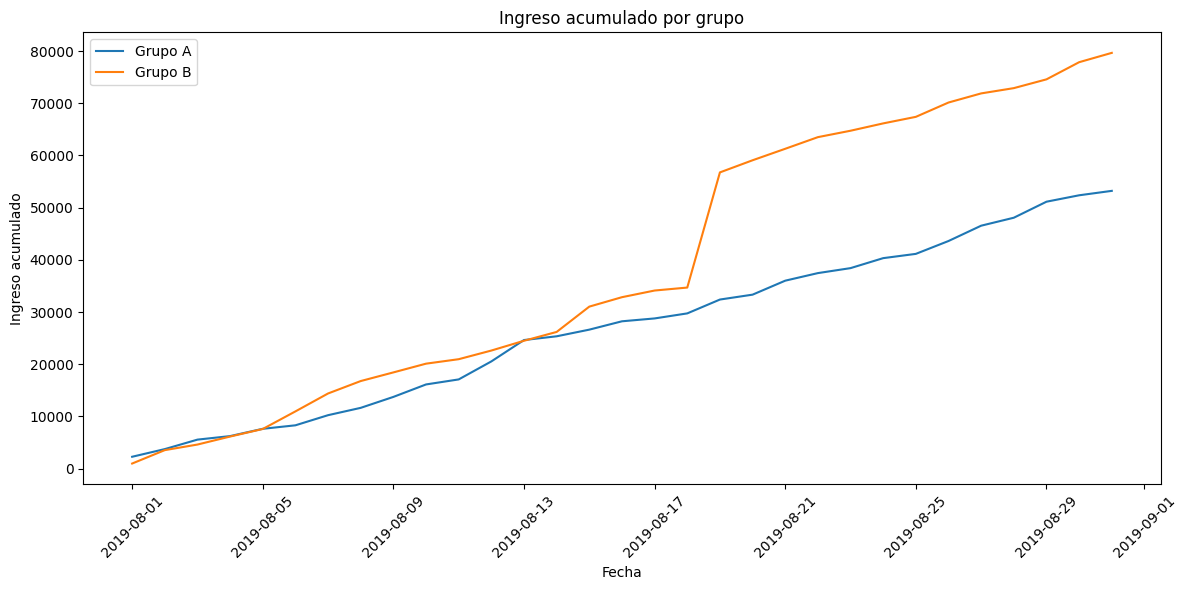

In [13]:
# Datos acumulados por grupo

cumulativeRevenueA = cumulativeData[
    cumulativeData['group'] == 'A'
][['date', 'revenue', 'transactionId']]

cumulativeRevenueB = cumulativeData[
    cumulativeData['group'] == 'B'
][['date', 'revenue', 'transactionId']]

# Gráfico del ingreso acumulado

plt.figure(figsize=(12, 6))

plt.plot(
    cumulativeRevenueA['date'],
    cumulativeRevenueA['revenue'],
    label='Grupo A'
)

plt.plot(
    cumulativeRevenueB['date'],
    cumulativeRevenueB['revenue'],
    label='Grupo B'
)

plt.title('Ingreso acumulado por grupo')
plt.xlabel('Fecha')
plt.ylabel('Ingreso acumulado')
plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Conclusión

El ingreso acumulado de ambos grupos presenta una tendencia creciente a lo largo del experimento. Sin embargo, el grupo **B** supera al grupo **A** aproximadamente a partir de la mitad del periodo analizado y mantiene esta ventaja hasta el final de la prueba.

Además, se observa un incremento pronunciado en el ingreso acumulado del grupo B alrededor del 19 de agosto, lo que podría estar asociado a uno o varios pedidos de alto valor. Esta situación sugiere la posible presencia de valores atípicos, los cuales serán analizados en secciones posteriores antes de extraer conclusiones definitivas sobre el desempeño de los grupos.

## Tamaño promedio de pedido acumulado por grupo

En esta sección se analizará la evolución del tamaño promedio de pedido acumulado para los grupos A y B. Esta métrica permite identificar si las diferencias en los ingresos acumulados se deben a pedidos de mayor valor o si ambos grupos presentan un comportamiento similar a lo largo del experimento.

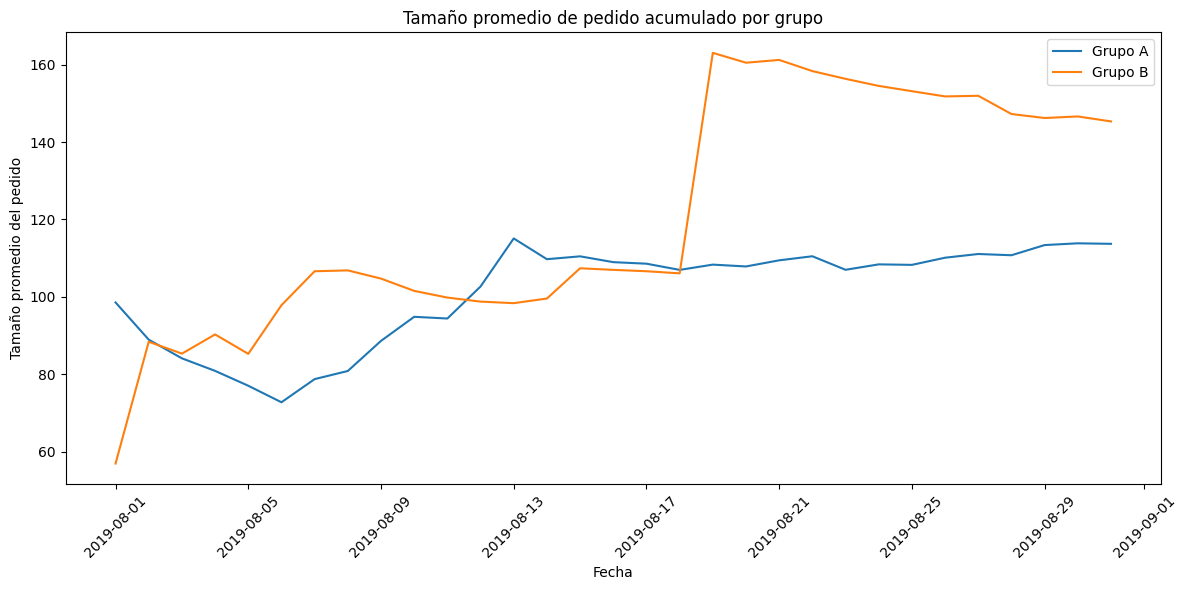

In [14]:
# Calcular el tamaño promedio de pedido acumulado

plt.figure(figsize=(12, 6))

plt.plot(
    cumulativeRevenueA['date'],
    cumulativeRevenueA['revenue'] / cumulativeRevenueA['transactionId'],
    label='Grupo A'
)

plt.plot(
    cumulativeRevenueB['date'],
    cumulativeRevenueB['revenue'] / cumulativeRevenueB['transactionId'],
    label='Grupo B'
)

plt.title('Tamaño promedio de pedido acumulado por grupo')
plt.xlabel('Fecha')
plt.ylabel('Tamaño promedio del pedido')

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Conclusión

El tamaño promedio de pedido acumulado presenta variaciones en ambos grupos durante el experimento. Sin embargo, alrededor del 19 de agosto el grupo **B** muestra un incremento considerable que lo mantiene por encima del grupo **A** hasta el final de la prueba.

Este comportamiento coincide con el aumento observado en el ingreso acumulado del grupo B y sugiere la posible influencia de uno o varios pedidos de alto valor. Por ello, antes de concluir que el grupo B presenta un mejor desempeño, será necesario analizar la presencia de valores atípicos y evaluar los resultados utilizando datos filtrados.

## Diferencia relativa en el tamaño promedio de pedido acumulado

En esta sección se representa la diferencia relativa en el tamaño promedio de pedido acumulado del grupo **B** con respecto al grupo **A**. Este gráfico permite identificar cuándo uno de los grupos presenta un mejor desempeño y evaluar si esa diferencia se mantiene estable durante el experimento.

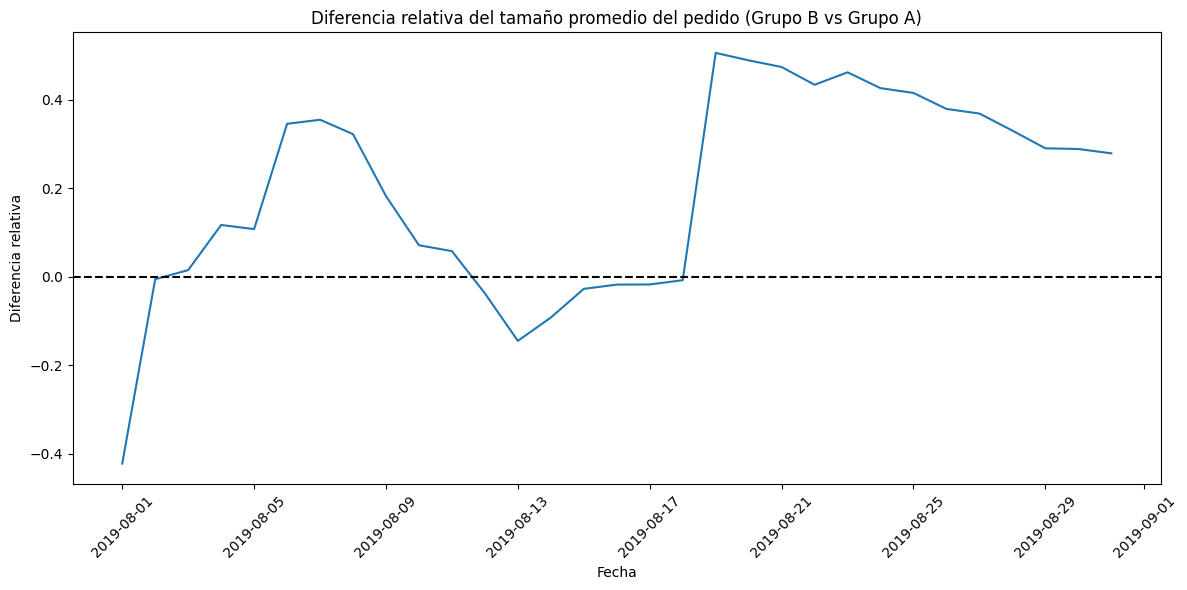

In [15]:
# Gráfico de la diferencia relativa en el tamaño promedio del pedido

mergedCumulativeRevenue = cumulativeRevenueA.merge(
    cumulativeRevenueB,
    left_on='date',
    right_on='date',
    suffixes=['A', 'B']
)

plt.figure(figsize=(12, 6))

plt.plot(
    mergedCumulativeRevenue['date'],
    (
        mergedCumulativeRevenue['revenueB']
        / mergedCumulativeRevenue['transactionIdB']
    ) /
    (
        mergedCumulativeRevenue['revenueA']
        / mergedCumulativeRevenue['transactionIdA']
    ) - 1
)

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Diferencia relativa del tamaño promedio del pedido (Grupo B vs Grupo A)')
plt.xlabel('Fecha')
plt.ylabel('Diferencia relativa')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Conclusión

La diferencia relativa en el tamaño promedio del pedido muestra un comportamiento variable durante la primera mitad del experimento. Sin embargo, a partir de la segunda mitad de la prueba el grupo **B** presenta una ventaja sostenida sobre el grupo **A**.

Destaca un incremento considerable alrededor del 19 de agosto, el cual coincide con los resultados observados en los gráficos de ingreso acumulado y tamaño promedio de pedido. Este comportamiento sugiere que la diferencia podría estar influenciada por pedidos de alto valor y no necesariamente por un cambio estable en el comportamiento de compra de los usuarios.

Por esta razón, será necesario analizar los valores atípicos antes de establecer conclusiones definitivas sobre el desempeño de los grupos.

## Tasa de conversión acumulada por grupo

En esta sección se calculará la tasa de conversión acumulada para cada grupo, definida como la relación entre el número acumulado de pedidos y el número acumulado de visitantes. Esta métrica permite evaluar qué tan efectiva fue cada variante para convertir visitantes en compradores a lo largo del experimento.

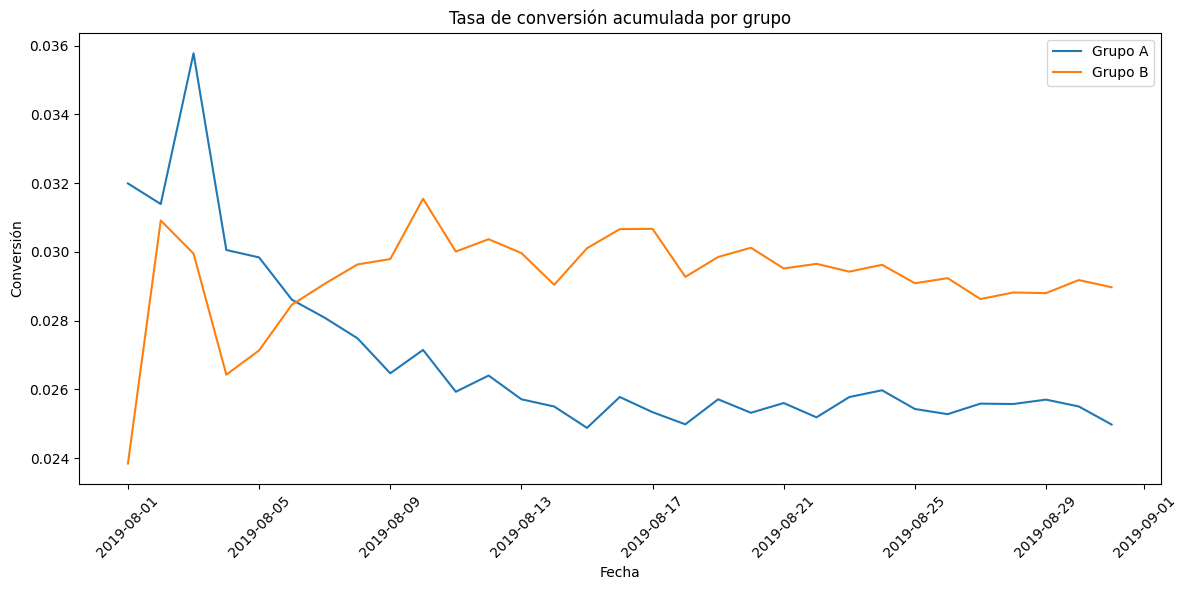

In [16]:
# Calcular la conversión acumulada

cumulativeData['conversion'] = (
    cumulativeData['transactionId']
    / cumulativeData['visits']
)

# Datos de conversión por grupo

cumulativeDataA = cumulativeData[
    cumulativeData['group'] == 'A'
]

cumulativeDataB = cumulativeData[
    cumulativeData['group'] == 'B'
]

# Gráfico de la conversión acumulada

plt.figure(figsize=(12, 6))

plt.plot(
    cumulativeDataA['date'],
    cumulativeDataA['conversion'],
    label='Grupo A'
)

plt.plot(
    cumulativeDataB['date'],
    cumulativeDataB['conversion'],
    label='Grupo B'
)

plt.title('Tasa de conversión acumulada por grupo')
plt.xlabel('Fecha')
plt.ylabel('Conversión')

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Conclusión

La tasa de conversión acumulada presenta fluctuaciones durante los primeros días del experimento, pero posteriormente ambas curvas se estabilizan. A partir de ese momento, el grupo **B** mantiene una tasa de conversión superior a la del grupo **A** durante la mayor parte del periodo analizado.

La diferencia observada sugiere que la variante B podría ser más efectiva para convertir visitantes en compradores. No obstante, será necesario realizar pruebas de significancia estadística para determinar si esta diferencia es suficientemente sólida.

## Número de pedidos por usuario

En esta sección se analizará la distribución del número de pedidos realizados por cada usuario mediante un gráfico de dispersión. El objetivo es identificar posibles valores atípicos y evaluar si existen usuarios con un comportamiento inusual que pueda influir en los resultados del experimento.

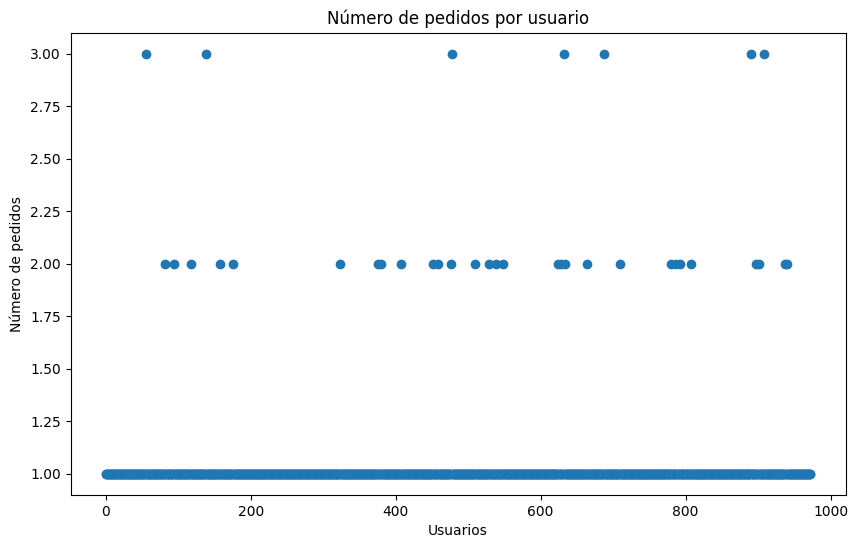

In [17]:
# Número de pedidos por usuario

ordersByUsers = (
    orders.groupby('visitorId', as_index=False)
    .agg({'transactionId': 'nunique'})
)

ordersByUsers.columns = ['visitorId', 'orders']

# Serie de números para el eje X

x_values = pd.Series(range(len(ordersByUsers)))

# Gráfico de dispersión

plt.figure(figsize=(10, 6))

plt.scatter(
    x_values,
    ordersByUsers['orders']
)

plt.title('Número de pedidos por usuario')
plt.xlabel('Usuarios')
plt.ylabel('Número de pedidos')

plt.show()

### Conclusión

El gráfico de dispersión muestra que la mayoría de los usuarios realizó un único pedido durante el periodo de análisis. Un grupo reducido efectuó dos pedidos y únicamente unos pocos usuarios alcanzaron tres pedidos.

Este comportamiento sugiere que los usuarios con tres pedidos podrían considerarse casos atípicos. No obstante, para establecer un umbral objetivo será necesario calcular los percentiles 95 y 99 del número de pedidos por usuario.

## Percentiles del número de pedidos por usuario

Se calcularán los percentiles 95 y 99 del número de pedidos por usuario con el objetivo de definir un criterio objetivo para identificar usuarios con un comportamiento atípico.

In [18]:
# Percentiles del número de pedidos por usuario

print(
    'Percentiles 95 y 99 del número de pedidos por usuario:',
    np.percentile(ordersByUsers['orders'], [95, 99])
)

Percentiles 95 y 99 del número de pedidos por usuario: [1. 2.]


### Conclusión

Los percentiles muestran que el 95% de los usuarios realizó un solo pedido y el 99% realizó como máximo dos pedidos durante el experimento.

Con base en estos resultados, se considerarán como usuarios anómalos aquellos que hayan realizado más de dos pedidos, ya que representan menos del 1% de la población analizada.

## Gráfico de dispersión de los precios de los pedidos

En esta sección se analizará la distribución de los ingresos de los pedidos mediante un gráfico de dispersión. Esto permitirá identificar visualmente la presencia de pedidos con valores excepcionalmente altos que podrían influir en los resultados del experimento.

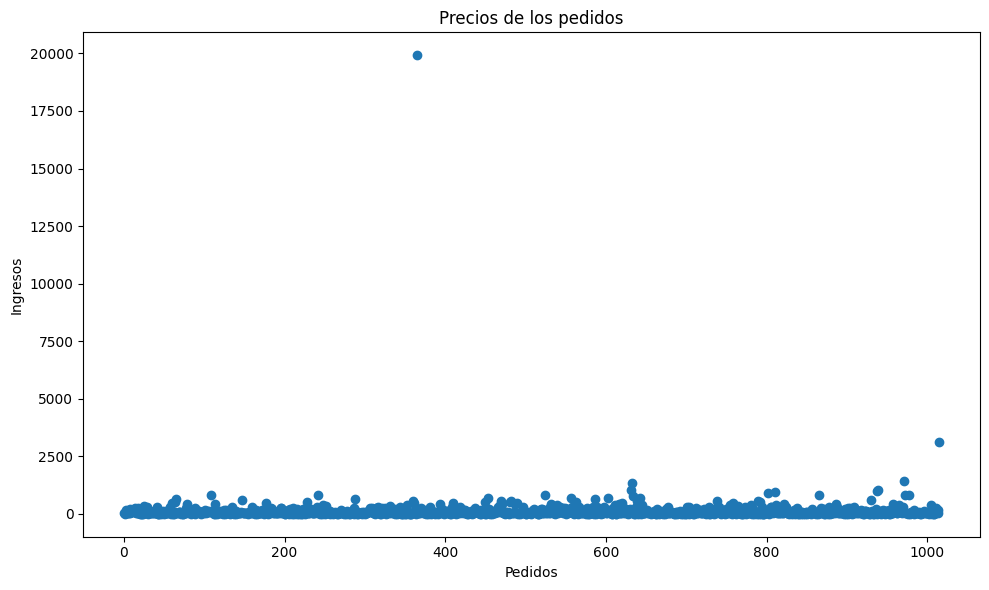

In [19]:
# Gráfico de dispersión de los precios de los pedidos

plt.figure(figsize=(10, 6))

plt.scatter(
    range(len(orders['revenue'])),
    orders['revenue']
)

plt.title('Precios de los pedidos')
plt.xlabel('Pedidos')
plt.ylabel('Ingresos')

plt.tight_layout()

plt.show()

### Conclusión

El gráfico de dispersión muestra que la mayoría de los pedidos presenta ingresos relativamente bajos y concentrados en un rango reducido. Sin embargo, se observan algunos pedidos con ingresos excepcionalmente altos, especialmente uno cercano a 20 000 unidades monetarias.

Estos valores atípicos podrían afectar el tamaño promedio de los pedidos, por lo que será necesario calcular los percentiles 95 y 99 para establecer un umbral objetivo que permita identificar anomalías.

## Percentiles de los precios de los pedidos

En esta sección se calcularán los percentiles 95 y 99 de los ingresos de los pedidos con el objetivo de establecer un criterio

In [20]:
# Percentiles de los precios de los pedidos

print(
    'Percentiles 95 y 99 de los precios de los pedidos:',
    np.percentile(orders['revenue'], [95, 99])
)

Percentiles 95 y 99 de los precios de los pedidos: [414.275 830.3  ]


### Conclusión

Los percentiles muestran que el 95% de los pedidos tiene un valor inferior a 414.275 y el 99% es menor o igual a 830.3.

Con base en estos resultados, se considerarán anómalos aquellos pedidos cuyo ingreso sea superior a 830.3, ya que representan únicamente una pequeña proporción de los datos y podrían distorsionar los resultados del análisis estadístico.

## Significancia estadística de la diferencia en la conversión

Se evaluará si existe una diferencia estadísticamente significativa en la tasa de conversión entre los grupos A y B utilizando los datos originales, sin eliminar valores atípicos. Para ello se aplicará la prueba no paramétrica de Mann-Whitney U.

In [21]:
# Preparación de los datos para comparar la conversión

ordersByUsersA = (
    orders[orders['group'] == 'A']
    .groupby('visitorId', as_index=False)
    .agg({'transactionId': 'nunique'})
)

ordersByUsersA.columns = ['visitorId', 'orders']

ordersByUsersB = (
    orders[orders['group'] == 'B']
    .groupby('visitorId', as_index=False)
    .agg({'transactionId': 'nunique'})
)

ordersByUsersB.columns = ['visitorId', 'orders']


sampleA = pd.concat(
    [
        ordersByUsersA['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'A']['visits'].sum() - len(ordersByUsersA)
            )
        )
    ],
    axis=0
)

sampleB = pd.concat(
    [
        ordersByUsersB['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'B']['visits'].sum() - len(ordersByUsersB)
            )
        )
    ],
    axis=0
)

In [22]:
print(
    'Valor p:',
    "{0:.3f}".format(stats.mannwhitneyu(sampleA, sampleB)[1])
)

print(
    'Diferencia relativa:',
    "{0:.3f}".format(sampleB.mean() / sampleA.mean() - 1)
)

Valor p: 0.011
Diferencia relativa: 0.160


### Conclusión

La prueba de Mann-Whitney arrojó un valor p de 0.011, inferior al nivel de significancia de 0.05. Por lo tanto, se rechaza la hipótesis nula y se concluye que existe una diferencia estadísticamente significativa en la tasa de conversión entre los grupos.

La diferencia relativa indica que el grupo B presenta una conversión aproximadamente un 16% superior a la del grupo A, lo que sugiere un mejor desempeño en esta métrica utilizando los datos sin filtrar.

## Significancia estadística de la diferencia en el tamaño promedio del pedido

En esta sección se evaluará si existe una diferencia estadísticamente significativa en el tamaño promedio de los pedidos entre los grupos A y B utilizando los datos originales, sin eliminar valores atípicos. Para ello se aplicará la prueba no paramétrica de Mann-Whitney U.

In [23]:
# Prueba de significancia estadística para el tamaño promedio del pedido (datos en bruto)

print(
    'Valor p:',
    "{0:.3f}".format(
        stats.mannwhitneyu(
            orders[orders['group'] == 'A']['revenue'],
            orders[orders['group'] == 'B']['revenue']
        )[1]
    )
)

print(
    'Diferencia relativa:',
    "{0:.3f}".format(
        orders[orders['group'] == 'B']['revenue'].mean() /
        orders[orders['group'] == 'A']['revenue'].mean() - 1
    )
)

Valor p: 0.862
Diferencia relativa: 0.278


### Conclusión

La prueba de Mann-Whitney arrojó un valor p de 0.862, superior al nivel de significancia de 0.05. Por lo tanto, no se rechaza la hipótesis nula y no existe evidencia estadísticamente significativa de una diferencia en el tamaño promedio de los pedidos entre los grupos.

Aunque la diferencia relativa muestra que el grupo B presenta un ingreso promedio por pedido aproximadamente un 27.8% mayor que el grupo A, esta diferencia puede estar influenciada por valores atípicos observados previamente, por lo que será necesario repetir el análisis utilizando los datos filtrados.

## Significancia estadística de la diferencia en la conversión (datos filtrados)

En esta sección se repetirá el análisis de la tasa de conversión después de eliminar los usuarios considerados anómalos. El objetivo es determinar si la diferencia observada entre los grupos se mantiene una vez que se reducen los posibles efectos de los valores atípicos.

In [24]:
# Identificación de usuarios anómalos

usersWithManyOrders = pd.concat(
    [
        ordersByUsersA[ordersByUsersA['orders'] > 2]['visitorId'],
        ordersByUsersB[ordersByUsersB['orders'] > 2]['visitorId']
    ],
    axis=0
)

usersWithExpensiveOrders = orders[
    orders['revenue'] > 830.3
]['visitorId']

abnormalUsers = (
    pd.concat(
        [usersWithManyOrders, usersWithExpensiveOrders],
        axis=0
    )
    .drop_duplicates()
    .sort_values()
)

print('Usuarios anómalos:', len(abnormalUsers))

Usuarios anómalos: 16


In [25]:
# Prueba de significancia estadística para la conversión (datos filtrados)

sampleAFiltered = pd.concat(
    [
        ordersByUsersA[
            ~ordersByUsersA['visitorId'].isin(abnormalUsers)
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'A']['visits'].sum()
                - len(ordersByUsersA)
            )
        )
    ],
    axis=0
)

sampleBFiltered = pd.concat(
    [
        ordersByUsersB[
            ~ordersByUsersB['visitorId'].isin(abnormalUsers)
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'B']['visits'].sum()
                - len(ordersByUsersB)
            )
        )
    ],
    axis=0
)

print(
    'Valor p:',
    "{0:.3f}".format(
        stats.mannwhitneyu(sampleAFiltered, sampleBFiltered)[1]
    )
)

print(
    'Diferencia relativa:',
    "{0:.3f}".format(
        sampleBFiltered.mean() / sampleAFiltered.mean() - 1
    )
)

Valor p: 0.007
Diferencia relativa: 0.189


El valor p obtenido fue de 0.007, menor que el nivel de significancia de 0.05. Por lo tanto, se rechaza la hipótesis nula y se concluye que existe una diferencia estadísticamente significativa en la tasa de conversión entre los grupos después de eliminar los usuarios anómalos.

Además, la diferencia relativa fue de 0.189, lo que indica que la tasa de conversión del grupo B es aproximadamente un 18.9% mayor que la del grupo A. Esto sugiere que la mejora observada en la conversión no depende únicamente de los valores atípicos y se mantiene incluso después del filtrado.

## Significancia estadística de la diferencia en el tamaño promedio del pedido (datos filtrados)

En esta sección se analizará si existe una diferencia estadísticamente significativa en el tamaño promedio de los pedidos entre los grupos A y B después de eliminar los usuarios considerados anómalos. Este análisis permitirá evaluar si las diferencias observadas en los datos originales se mantienen una vez reducida la influencia de los valores atípicos.

In [26]:
# Ingresos de los pedidos después de eliminar los usuarios anómalos

sampleAFiltered = orders[
    np.logical_and(
        orders['group'] == 'A',
        np.logical_not(
            orders['visitorId'].isin(abnormalUsers)
        )
    )
]['revenue']

sampleBFiltered = orders[
    np.logical_and(
        orders['group'] == 'B',
        np.logical_not(
            orders['visitorId'].isin(abnormalUsers)
        )
    )
]['revenue']

In [27]:
# Prueba de Mann-Whitney para el tamaño promedio del pedido (datos filtrados)

print(
    'Valor p:',
    "{0:.3f}".format(
        stats.mannwhitneyu(sampleAFiltered, sampleBFiltered)[1]
    )
)

print(
    'Diferencia relativa:',
    "{0:.3f}".format(
        sampleBFiltered.mean() / sampleAFiltered.mean() - 1
    )
)

Valor p: 0.822
Diferencia relativa: -0.032


### Conclusión

La prueba de Mann-Whitney arrojó un valor p de **0.822**, superior al nivel de significancia de **0.05**. Por lo tanto, no existe evidencia estadísticamente significativa de una diferencia en el tamaño promedio de los pedidos entre los grupos después de eliminar los usuarios anómalos.

Asimismo, la diferencia relativa pasó de un **27.8%** en los datos originales a **-3.2%** en los datos filtrados. Esto indica que la aparente ventaja observada inicialmente para el grupo B estaba influenciada por unos pocos pedidos de alto valor y que, al eliminar las anomalías, ambos grupos presentan un comportamiento muy similar en cuanto al tamaño promedio de los pedidos.

# Decisión final del experimento

Con base en los resultados obtenidos, la decisión recomendada es **detener la prueba y considerar al grupo B como líder**.

La tasa de conversión del grupo B fue significativamente superior tanto en los datos originales como en los datos filtrados. Después de eliminar los usuarios anómalos, la prueba de Mann-Whitney arrojó un **valor p de 0.007**, inferior al nivel de significancia de 0.05, lo que confirma que la diferencia en la conversión es estadísticamente significativa.

Por otro lado, el tamaño promedio de los pedidos no presentó diferencias estadísticamente significativas entre los grupos. Tras el filtrado de los datos, el **valor p fue de 0.822**, muy por encima de 0.05, lo que indica que ambos grupos tienen un comportamiento similar respecto al importe promedio de los pedidos.

Durante el análisis también se identificaron **58 usuarios presentes en ambos grupos**, por lo que fueron eliminados para evitar sesgos en la prueba A/B. Asimismo, se excluyeron **16 usuarios anómalos**, identificados por presentar un número inusualmente alto de pedidos o valores de compra atípicos. El hecho de que la superioridad del grupo B en la conversión se mantuviera incluso después de estas depuraciones fortalece la confianza en los resultados obtenidos.

En conjunto, la evidencia indica que el grupo B genera una mayor tasa de conversión sin afectar negativamente el tamaño promedio de los pedidos. Por ello, la decisión más adecuada es finalizar la prueba e implementar la variante correspondiente al grupo B.